In [32]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/word2vec-nlp-tutorial/testData.tsv.zip
/kaggle/input/competitions/word2vec-nlp-tutorial/sampleSubmission.csv
/kaggle/input/competitions/word2vec-nlp-tutorial/unlabeledTrainData.tsv.zip
/kaggle/input/competitions/word2vec-nlp-tutorial/labeledTrainData.tsv.zip


In [33]:

import pandas as pd

# 读取带有情感标签的电影评论数据
train = pd.read_csv(
    '/kaggle/input/competitions/word2vec-nlp-tutorial/labeledTrainData.tsv.zip',
    sep='\t',
    compression='zip'
)

# 查看数据的行数和列数
print("数据集的形状：", train.shape)

# 查看数据的列名
print("\n数据集的列名：")
print(train.columns.tolist())

# 查看前五条评论的基本信息
print("\n前五条评论：")
print(train[['id', 'sentiment']].head())

# 查看第一条电影评论
print("\n第一条电影评论：")
print(train['review'].iloc[0][:500])


数据集的形状： (25000, 3)

数据集的列名：
['id', 'sentiment', 'review']

前五条评论：
       id  sentiment
0  5814_8          1
1  2381_9          1
2  7759_3          0
3  3630_4          0
4  9495_8          1

第一条电影评论：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it has subtle messa


In [34]:

from sklearn.feature_extraction.text import CountVectorizer

# 准备三条电影评论
reviews = [
    "This movie is good",
    "This movie is bad",
    "This movie is very good"
]

# 创建词袋模型
vectorizer = CountVectorizer()

# 学习词汇表，并把文本转换成词频矩阵
X = vectorizer.fit_transform(reviews)

# 查看词汇表
print("词汇表：")
print(vectorizer.get_feature_names_out())

# 查看向量矩阵
print("\n词频矩阵：")
print(X.toarray())

# 查看矩阵的维度
print("\n矩阵形状：")
print(X.shape)


词汇表：
['bad' 'good' 'is' 'movie' 'this' 'very']

词频矩阵：
[[0 1 1 1 1 0]
 [1 0 1 1 1 0]
 [0 1 1 1 1 1]]

矩阵形状：
(3, 6)


In [35]:

# 统计正面和负面评论的数量
sentiment_counts = train['sentiment'].value_counts()

print("情感标签数量：")
print(sentiment_counts)

# 计算各类别所占比例
sentiment_percent = train['sentiment'].value_counts(normalize=True) * 100

print("\n情感标签比例：")
print(sentiment_percent)


情感标签数量：
sentiment
1    12500
0    12500
Name: count, dtype: int64

情感标签比例：
sentiment
1    50.0
0    50.0
Name: proportion, dtype: float64


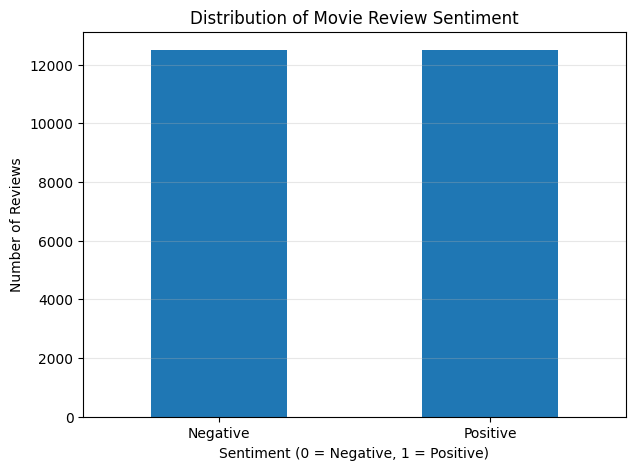

In [36]:

import matplotlib.pyplot as plt

# 绘制正面和负面评论数量分布图
plt.figure(figsize=(7, 5))

sentiment_counts.sort_index().plot(
    kind='bar',
    rot=0
)

plt.title('Distribution of Movie Review Sentiment')
plt.xlabel('Sentiment (0 = Negative, 1 = Positive)')
plt.ylabel('Number of Reviews')
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.grid(axis='y', alpha=0.3)

plt.show()


In [37]:

# 计算每条电影评论的字符长度
train['review_length'] = train['review'].apply(len)

# 查看评论长度的统计信息
print("电影评论长度统计：")
print(train['review_length'].describe())


电影评论长度统计：
count    25000.000000
mean      1327.710560
std       1005.239246
min         52.000000
25%        703.000000
50%        981.000000
75%       1617.000000
max      13708.000000
Name: review_length, dtype: float64


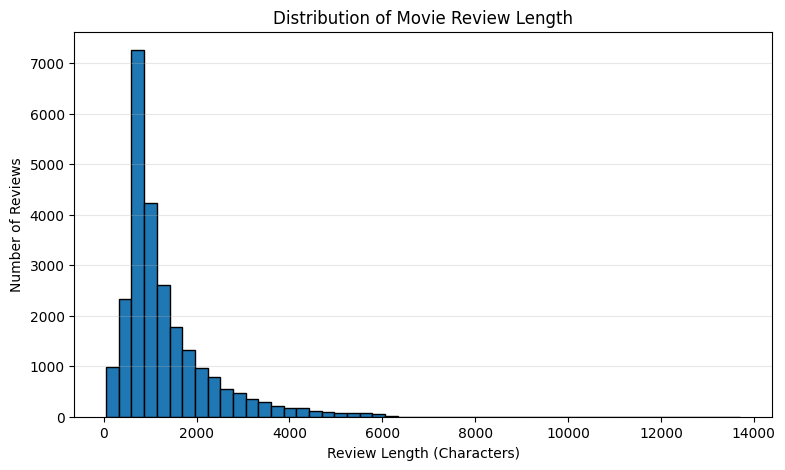

In [38]:

import matplotlib.pyplot as plt

# 绘制电影评论长度分布直方图
plt.figure(figsize=(9, 5))

plt.hist(
    train['review_length'],
    bins=50,
    edgecolor='black'
)

plt.title('Distribution of Movie Review Length')
plt.xlabel('Review Length (Characters)')
plt.ylabel('Number of Reviews')

plt.grid(axis='y', alpha=0.3)
plt.show()


In [39]:

# 查看第一条原始电影评论
print("第一条电影评论：")
print(train['review'].iloc[0])

# 查看第二条原始电影评论
print("\n第二条电影评论：")
print(train['review'].iloc[1])


第一条电影评论：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it has subtle messages about MJ's feeling towards the press and also the obvious message of drugs are bad m'kay.<br /><br />Visually impressive but of course this is all about Michael Jackson so unless you remotely like MJ in anyway then you are going to hate this and find it boring. Some may call MJ an egotist for consenting to the making of this movie BUT MJ and most of his fans would say that he made it for the fans which if true is really nice of him.<br /><br />The actual feature film bit when it fin

In [40]:

# 查看评论中是否存在HTML标签
sample = train['review'].iloc[0]

print("是否包含HTML标签：")
print('<' in sample and '>' in sample)

print("\n原始评论前500个字符：")
print(sample[:500])


是否包含HTML标签：
True

原始评论前500个字符：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it has subtle messa


In [41]:

# 导入 BeautifulSoup
from bs4 import BeautifulSoup

# 获取第一条原始电影评论
sample = train['review'].iloc[0]

# 使用 BeautifulSoup 解析 HTML
soup = BeautifulSoup(sample, 'html.parser')

# 提取 HTML 标签中的纯文本
clean_text = soup.get_text()

# 对比清理前后的结果
print("原始评论：")
print(sample[:500])

print("\n清理后的评论：")
print(clean_text[:500])


原始评论：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it has subtle messa

清理后的评论：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make up my mind whether he is guilty or innocent. Moonwalker is part biography, part feature film which i remember going to see at the cinema when it was originally released. Some of it 

In [42]:

# 查找第一条评论中第一个左尖括号
position = sample.find('<')

print("左尖括号的位置：", position)

# 查看尖括号附近的内容
if position != -1:
    print("\n附近的原始文本：")
    print(sample[max(0, position-50):position+150])
else:
    print("没有找到左尖括号")

# 对比清理前后的长度
print("\n原始评论长度：", len(sample))
print("清理后评论长度：", len(clean_text))


左尖括号的位置： 593

附近的原始文本：
d also the obvious message of drugs are bad m'kay.<br /><br />Visually impressive but of course this is all about Michael Jackson so unless you remotely like MJ in anyway then you are going to hate th

原始评论长度： 2302
清理后评论长度： 2254


In [43]:

import re
from bs4 import BeautifulSoup

# 定义一个文本清洗函数
def clean_review(text):

    # 1. 删除 HTML 标签
    text = BeautifulSoup(text, 'html.parser').get_text()

    # 2. 将所有字母转换成小写
    text = text.lower()

    # 3. 删除非字母字符，保留英文字母和空格
    text = re.sub(r'[^a-z\s]', ' ', text)

    # 4. 删除多余空格
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# 对全部电影评论进行清洗
train['clean_review'] = train['review'].apply(clean_review)

# 查看清洗前后的结果
print("原始评论：")
print(train['review'].iloc[0][:300])

print("\n清洗后的评论：")
print(train['clean_review'].iloc[0][:300])

# 查看清洗前后的长度
print("\n原始长度：", len(train['review'].iloc[0]))
print("清洗后长度：", len(train['clean_review'].iloc[0]))


原始评论：
With all this stuff going down at the moment with MJ i've started listening to his music, watching the odd documentary here and there, watched The Wiz and watched Moonwalker again. Maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe ma

清洗后的评论：
with all this stuff going down at the moment with mj i ve started listening to his music watching the odd documentary here and there watched the wiz and watched moonwalker again maybe i just want to get a certain insight into this guy who i thought was really cool in the eighties just to maybe make 

原始长度： 2302
清洗后长度： 2221


In [44]:

import nltk

# 下载英文停用词库
nltk.download('stopwords')

# 导入英文停用词
from nltk.corpus import stopwords

# 获取英文停用词列表
stops = stopwords.words('english')

# 查看前30个停用词
print("英文停用词示例：")
print(stops[:30])

# 查看停用词总数
print("\n停用词总数：", len(stops))


英文停用词示例：
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't"]

停用词总数： 198


[nltk_data] Error loading stopwords: <urlopen error [Errno -3]
[nltk_data]     Temporary failure in name resolution>


In [45]:

# 获取第一条清洗后的电影评论
sample_text = train['clean_review'].iloc[0]

# 将评论拆分成单词
words = sample_text.split()

# 删除停用词
meaningful_words = [
    word for word in words if word not in stops
]

# 输出处理前后的结果
print("原始单词：")
print(words[:40])

print("\n删除停用词后的单词：")
print(meaningful_words[:40])

# 比较单词数量
print("\n原始单词数量：", len(words))
print("删除停用词后：", len(meaningful_words))


原始单词：
['with', 'all', 'this', 'stuff', 'going', 'down', 'at', 'the', 'moment', 'with', 'mj', 'i', 've', 'started', 'listening', 'to', 'his', 'music', 'watching', 'the', 'odd', 'documentary', 'here', 'and', 'there', 'watched', 'the', 'wiz', 'and', 'watched', 'moonwalker', 'again', 'maybe', 'i', 'just', 'want', 'to', 'get', 'a', 'certain']

删除停用词后的单词：
['stuff', 'going', 'moment', 'mj', 'started', 'listening', 'music', 'watching', 'odd', 'documentary', 'watched', 'wiz', 'watched', 'moonwalker', 'maybe', 'want', 'get', 'certain', 'insight', 'guy', 'thought', 'really', 'cool', 'eighties', 'maybe', 'make', 'mind', 'whether', 'guilty', 'innocent', 'moonwalker', 'part', 'biography', 'part', 'feature', 'film', 'remember', 'going', 'see', 'cinema']

原始单词数量： 437
删除停用词后： 219


In [46]:

# 导入词袋模型工具
from sklearn.feature_extraction.text import CountVectorizer

# 比如说我准备三条简单的电影评论
documents = [
    "I like this movie",
    "I like this film",
    "I hate this movie"
]

# 创建词袋模型
vectorizer = CountVectorizer()

# 学习词汇表，并将文本转换成词频矩阵
X = vectorizer.fit_transform(documents)

# 查看词汇表
print("词汇表：")
print(vectorizer.get_feature_names_out())

# 查看词频矩阵
print("\n词频矩阵：")
print(X.toarray())

# 查看矩阵形状
print("\n矩阵形状：")
print(X.shape)


词汇表：
['film' 'hate' 'like' 'movie' 'this']

词频矩阵：
[[0 0 1 1 1]
 [1 0 1 0 1]
 [0 1 0 1 1]]

矩阵形状：
(3, 5)


In [47]:

# 导入词袋模型工具
from sklearn.feature_extraction.text import CountVectorizer

# 创建词袋模型
vectorizer = CountVectorizer()

# 使用清洗后的25000条电影评论建立词汇表
# 并将所有评论转换成词频矩阵
X_bow = vectorizer.fit_transform(train['clean_review'])

# 获取整个数据集的词汇表
vocabulary = vectorizer.get_feature_names_out()

# 查看数据集的基本信息
print("电影评论数量：", train.shape[0])
print("词汇表大小：", len(vocabulary))
print("词频矩阵形状：", X_bow.shape)

# 查看前20个词汇
print("\n词汇表前20个单词：")
print(vocabulary[:20])

# 查看前3条评论对应的前20个词汇的词频
print("\n前3条评论的部分词频矩阵：")
print(X_bow[:3, :20].toarray())

# 查看整个矩阵中非零元素的数量
print("\n词频矩阵中的非零元素数量：", X_bow.nnz)

# 计算矩阵的稀疏程度
total_elements = X_bow.shape[0] * X_bow.shape[1]
sparsity = (1 - X_bow.nnz / total_elements) * 100

print("矩阵稀疏率：", round(sparsity, 2), "%")


电影评论数量： 25000
词汇表大小： 74192
词频矩阵形状： (25000, 74192)

词汇表前20个单词：
['aa' 'aaa' 'aaaaaaah' 'aaaaah' 'aaaaatch' 'aaaahhhhhhh' 'aaaand'
 'aaaarrgh' 'aaah' 'aaargh' 'aaaugh' 'aaawwwwnnn' 'aachen' 'aada' 'aadha'
 'aag' 'aage' 'aaghh' 'aah' 'aahhh']

前3条评论的部分词频矩阵：
[[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]]

词频矩阵中的非零元素数量： 3409936
矩阵稀疏率： 99.82 %


In [48]:

# 导入TF-IDF工具
from sklearn.feature_extraction.text import TfidfVectorizer

# 创建TF-IDF模型
tfidf_vectorizer = TfidfVectorizer()

# 将25000条评论转换为TF-IDF矩阵
X_tfidf = tfidf_vectorizer.fit_transform(train['clean_review'])

# 查看矩阵形状
print("TF-IDF矩阵形状：", X_tfidf.shape)

# 查看非零元素数量
print("非零元素数量：", X_tfidf.nnz)

# 查看第一条评论的前20个特征值
print("\n第一条评论的部分TF-IDF值：")
print(X_tfidf[0, :20].toarray())


TF-IDF矩阵形状： (25000, 74192)
非零元素数量： 3409936

第一条评论的部分TF-IDF值：
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [49]:

# 获取完整的词汇表
feature_names = tfidf_vectorizer.get_feature_names_out()

# 提取第一条评论对应的TF-IDF向量
first_review = X_tfidf.getrow(0)

# 找出第一条评论中实际出现的单词及其TF-IDF权重
print("第一条评论的TF-IDF特征：\n")

for index, score in zip(first_review.indices, first_review.data):
    print(feature_names[index], ":", round(score, 4))

# 查看第一条评论中权重最高的10个单词
top_indices = first_review.data.argsort()[::-1][:10]

print("\n权重最高的10个单词：")

for i in top_indices:
    index = first_review.indices[i]
    score = first_review.data[i]
    print(feature_names[index], ":", round(score, 4))


第一条评论的TF-IDF特征：

with : 0.0406
all : 0.0492
this : 0.0903
stuff : 0.0312
going : 0.0672
down : 0.023
at : 0.0248
the : 0.1431
moment : 0.0317
mj : 0.7171
ve : 0.0424
started : 0.0325
listening : 0.0442
to : 0.0714
his : 0.0415
music : 0.0505
watching : 0.0215
odd : 0.0366
documentary : 0.035
here : 0.0205
and : 0.0772
there : 0.0137
watched : 0.0528
wiz : 0.0667
moonwalker : 0.1239
again : 0.0227
maybe : 0.0792
just : 0.0417
want : 0.023
get : 0.0172
certain : 0.0342
insight : 0.0443
into : 0.0352
guy : 0.0511
who : 0.0401
thought : 0.0235
was : 0.0215
really : 0.0327
cool : 0.0658
in : 0.0336
eighties : 0.0497
make : 0.018
up : 0.0154
my : 0.0159
mind : 0.0271
whether : 0.0333
he : 0.1264
is : 0.1325
guilty : 0.0884
or : 0.0562
innocent : 0.0387
part : 0.0457
biography : 0.0517
feature : 0.0683
film : 0.0237
which : 0.0492
remember : 0.0287
see : 0.0159
cinema : 0.0302
when : 0.0452
it : 0.0666
originally : 0.0409
released : 0.0323
some : 0.0292
of : 0.0864
has : 0.0143
subtle : 0.038

In [50]:

# 获取第一条评论的BoW向量
first_bow = X_bow.getrow(0)

# 获取第一条评论的TF-IDF向量
first_tfidf = X_tfidf.getrow(0)

# 获取词汇表
feature_names = vectorizer.get_feature_names_out()

# 找到第一条评论中出现次数最多的10个词
bow_order = first_bow.data.argsort()[::-1][:10]

print("BoW词频排名前10：")

for i in bow_order:
    word_index = first_bow.indices[i]
    print(feature_names[word_index], ":", first_bow.data[i])

# 找到TF-IDF权重最高的10个词
tfidf_order = first_tfidf.data.argsort()[::-1][:10]

print("\nTF-IDF权重排名前10：")

for i in tfidf_order:
    word_index = first_tfidf.indices[i]
    print(feature_names[word_index], ":", round(first_tfidf.data[i], 4))


BoW词频排名前10：
the : 19
is : 16
mj : 11
of : 11
this : 11
and : 10
to : 9
he : 9
it : 8
people : 5

TF-IDF权重排名前10：
mj : 0.7171
the : 0.1431
is : 0.1325
he : 0.1264
moonwalker : 0.1239
pesci : 0.1207
sequence : 0.1024
this : 0.0903
people : 0.0893
jackson : 0.0885


In [51]:

# 导入 Word2Vec 模型
from gensim.models import Word2Vec

print("Word2Vec 导入成功！")


Word2Vec 导入成功！


In [52]:

# 将25000条电影评论转换成单词列表
sentences = train['clean_review'].fillna('').apply(
    lambda x: x.split()
).tolist()

# 查看第一条评论的前30个单词
print("第一条评论的前30个单词：")
print(sentences[0][:30])

# 查看评论总数
print("\n评论总数：", len(sentences))

# 查看第一条评论的单词数量
print("第一条评论的单词数量：", len(sentences[0]))


第一条评论的前30个单词：
['with', 'all', 'this', 'stuff', 'going', 'down', 'at', 'the', 'moment', 'with', 'mj', 'i', 've', 'started', 'listening', 'to', 'his', 'music', 'watching', 'the', 'odd', 'documentary', 'here', 'and', 'there', 'watched', 'the', 'wiz', 'and', 'watched']

评论总数： 25000
第一条评论的单词数量： 437


In [53]:

# 创建并训练 Word2Vec 模型
model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=4,
    sg=1,
    epochs=10
)

print("Word2Vec 模型训练完成！")

# 查看词汇表大小
print("词汇表大小：", len(model.wv))

# 查看 movie 对应的词向量
print("movie 的词向量：")
print(model.wv['movie'])

# 查看词向量维度
print("词向量维度：", model.wv['movie'].shape)


Word2Vec 模型训练完成！
词汇表大小： 28757
movie 的词向量：
[ 1.25788048e-01 -6.70688227e-02  4.70499471e-02  4.96770032e-02
  4.50965136e-01 -1.09905452e-01  9.21029970e-02  2.17495114e-01
 -4.74018514e-01 -4.57998544e-01  1.83928892e-01 -2.74428964e-01
  1.04716066e-02  1.82009533e-01 -2.84795135e-01  6.42408395e-06
  1.61161631e-01  2.93380558e-01 -6.02786578e-02 -6.42590582e-01
  8.42665285e-02  1.12080470e-01 -1.16178378e-01 -4.17937398e-01
  2.52000064e-01  1.41452730e-01 -3.31020564e-01  3.79733816e-02
 -9.41665396e-02 -4.09694672e-01  1.40257165e-01 -1.05802365e-01
  2.31410906e-01 -1.85691401e-01 -2.16025785e-01  2.55915940e-01
  2.05305427e-01  3.81262712e-02 -7.56385177e-02 -4.57817852e-01
  1.03134446e-01  4.57305878e-01 -1.41063966e-02 -1.07777126e-01
  3.11031729e-01 -8.03549066e-02 -3.82676125e-01 -1.53870910e-01
  9.65753496e-02  2.83188522e-02 -1.55605823e-01 -5.25513804e-03
 -1.73958063e-01 -1.28623396e-02  8.99714185e-04  3.60247716e-02
  3.23905677e-01 -1.95998013e-01 -1.67894632e-01

In [54]:

# 查找与 movie 最相似的10个单词
similar_words = model.wv.most_similar(
    'movie',
    topn=10
)

print("与 movie 最相似的10个单词：")

for word, similarity in similar_words:
    print(word, ":", round(similarity, 4))


与 movie 最相似的10个单词：
film : 0.906
flick : 0.7678
sequal : 0.7055
it : 0.7035
dcom : 0.7006
crapfest : 0.6938
lotta : 0.6929
yawner : 0.6901
snoozer : 0.6897
bummed : 0.6887


In [55]:

# 测试不同单词的语义相似关系

test_words = ['movie', 'good', 'bad', 'actor', 'music']

for word in test_words:
    print("\n与", word, "最相似的5个单词：")

    similar = model.wv.most_similar(
        word,
        topn=5
    )

    for similar_word, score in similar:
        print(similar_word, ":", round(score, 4))



与 movie 最相似的5个单词：
film : 0.906
flick : 0.7678
sequal : 0.7055
it : 0.7035
dcom : 0.7006

与 good 最相似的5个单词：
decent : 0.7932
great : 0.7768
bad : 0.7661
nice : 0.6887
fine : 0.6854

与 bad 最相似的5个单词：
terrible : 0.7862
good : 0.7661
horrible : 0.7569
awful : 0.7263
lousy : 0.7136

与 actor 最相似的5个单词：
actress : 0.7248
comedian : 0.6786
impersonation : 0.657
performance : 0.6524
role : 0.6495

与 music 最相似的5个单词：
soundtrack : 0.8419
songs : 0.7259
melodious : 0.7259
score : 0.7243
synthesizer : 0.7011


In [56]:
# 比较 good 和 bad 与其他词的相似度

words = ['good', 'bad', 'great', 'terrible']

for word in words:
    print("\n当前单词：", word)

    for target in ['good', 'bad', 'great', 'terrible']:
        if word != target:
            score = model.wv.similarity(word, target)
            print(target, ":", round(score, 4))


当前单词： good
bad : 0.7661
great : 0.7768
terrible : 0.5871

当前单词： bad
good : 0.7661
great : 0.5177
terrible : 0.7862

当前单词： great
good : 0.7768
bad : 0.5177
terrible : 0.5145

当前单词： terrible
good : 0.5871
bad : 0.7862
great : 0.5145


In [61]:
# 查看 Word2Vec 模型的训练参数

print("训练方式：", "Skip-gram" if model.sg == 1 else "CBOW")
print("词向量维度：", model.vector_size)
print("上下文窗口：", model.window)
print("训练轮数：", model.epochs)

# 查看词汇表大小
print("词汇表大小：", len(model.wv))

# 查看 movie 对应的词向量
print("\nmovie 的词向量：")
print(model.wv['movie'])

# 查看词向量的形状
print("\n向量形状：", model.wv['movie'].shape)

训练方式： Skip-gram
词向量维度： 100
上下文窗口： 5
训练轮数： 10
词汇表大小： 28757

movie 的词向量：
[ 1.25788048e-01 -6.70688227e-02  4.70499471e-02  4.96770032e-02
  4.50965136e-01 -1.09905452e-01  9.21029970e-02  2.17495114e-01
 -4.74018514e-01 -4.57998544e-01  1.83928892e-01 -2.74428964e-01
  1.04716066e-02  1.82009533e-01 -2.84795135e-01  6.42408395e-06
  1.61161631e-01  2.93380558e-01 -6.02786578e-02 -6.42590582e-01
  8.42665285e-02  1.12080470e-01 -1.16178378e-01 -4.17937398e-01
  2.52000064e-01  1.41452730e-01 -3.31020564e-01  3.79733816e-02
 -9.41665396e-02 -4.09694672e-01  1.40257165e-01 -1.05802365e-01
  2.31410906e-01 -1.85691401e-01 -2.16025785e-01  2.55915940e-01
  2.05305427e-01  3.81262712e-02 -7.56385177e-02 -4.57817852e-01
  1.03134446e-01  4.57305878e-01 -1.41063966e-02 -1.07777126e-01
  3.11031729e-01 -8.03549066e-02 -3.82676125e-01 -1.53870910e-01
  9.65753496e-02  2.83188522e-02 -1.55605823e-01 -5.25513804e-03
 -1.73958063e-01 -1.28623396e-02  8.99714185e-04  3.60247716e-02
  3.23905677e-01 -1

In [62]:

import numpy as np

# 将一条评论转换为平均词向量
def makeFeatureVec(words, model, num_features):

    # 创建一个全零向量，长度为100
    featureVec = np.zeros((num_features,), dtype="float32")

    # 统计有多少个单词成功找到对应的词向量
    nwords = 0

    # 获取模型词汇表，转换成集合，提高查找速度
    index2word_set = set(model.wv.key_to_index.keys())

    # 遍历评论中的每一个单词
    for word in words:

        # 如果这个单词存在于Word2Vec词汇表中
        if word in index2word_set:

            # 单词数量加1
            nwords += 1

            # 将这个单词的词向量累加到总向量中
            featureVec = np.add(featureVec, model.wv[word])

    # 如果找到了有效单词，就计算平均值
    if nwords > 0:
        featureVec = np.divide(featureVec, nwords)

    return featureVec


In [64]:

# 将整个评论数据集转换为平均词向量矩阵
def getAvgFeatureVecs(reviews, model, num_features):

    # 创建一个二维数组，保存所有评论的向量
    reviewFeatureVecs = np.zeros(
        (len(reviews), num_features),
        dtype="float32"
    )

    # 遍历所有评论
    for i, review in enumerate(reviews):

        # 每处理1000条评论，输出一次进度
        if i % 1000 == 0:
            print("Review %d of %d" % (i, len(reviews)))

        # 调用刚才的函数，计算当前评论的平均向量
        reviewFeatureVecs[i] = makeFeatureVec(
            review, model, num_features
        )

    return reviewFeatureVecs


In [65]:
# 设置词向量维度
num_features = 100

# 将25000条电影评论转换为平均词向量
trainDataVecs = getAvgFeatureVecs(
    sentences,
    model,
    num_features
)

# 查看最终结果
print("训练数据特征矩阵形状：", trainDataVecs.shape)
print("第一条评论的向量：")
print(trainDataVecs[0])

Review 0 of 25000
Review 1000 of 25000
Review 2000 of 25000
Review 3000 of 25000
Review 4000 of 25000
Review 5000 of 25000
Review 6000 of 25000
Review 7000 of 25000
Review 8000 of 25000
Review 9000 of 25000
Review 10000 of 25000
Review 11000 of 25000
Review 12000 of 25000
Review 13000 of 25000
Review 14000 of 25000
Review 15000 of 25000
Review 16000 of 25000
Review 17000 of 25000
Review 18000 of 25000
Review 19000 of 25000
Review 20000 of 25000
Review 21000 of 25000
Review 22000 of 25000
Review 23000 of 25000
Review 24000 of 25000
训练数据特征矩阵形状： (25000, 100)
第一条评论的向量：
[-0.05805075  0.14996381  0.02312373  0.14379743  0.04768652 -0.16183697
  0.08915561  0.28308615 -0.2322245  -0.15863965  0.02315508 -0.16513917
  0.00363528  0.03928562  0.1264449  -0.06217874  0.15356697 -0.03966341
 -0.05929764 -0.44832602  0.09871426  0.04150259  0.1494057  -0.2261183
  0.10883988  0.02303159 -0.07061718 -0.02066007 -0.0636003  -0.13637108
  0.15506445 -0.16993318  0.06714702 -0.18959646 -0.0308342   0.

In [67]:
import glob

# 在Kaggle数据目录中查找测试集
test_files = glob.glob(
    '/kaggle/input/**/testData.tsv',
    recursive=True
)

print("找到的测试集文件：", test_files)

找到的测试集文件： []


In [68]:
import os

# 查看 Kaggle 输入目录中的所有数据集
for root, dirs, files in os.walk('/kaggle/input'):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/competitions/word2vec-nlp-tutorial/testData.tsv.zip
/kaggle/input/competitions/word2vec-nlp-tutorial/sampleSubmission.csv
/kaggle/input/competitions/word2vec-nlp-tutorial/unlabeledTrainData.tsv.zip
/kaggle/input/competitions/word2vec-nlp-tutorial/labeledTrainData.tsv.zip


In [69]:
import zipfile
import os

# Kaggle 数据集目录
data_dir = '/kaggle/input/competitions/word2vec-nlp-tutorial/'

# 解压到工作目录
extract_dir = '/kaggle/working/data'
os.makedirs(extract_dir, exist_ok=True)

# 解压三个数据集
zip_files = [
    'testData.tsv.zip',
    'labeledTrainData.tsv.zip',
    'unlabeledTrainData.tsv.zip'
]

for filename in zip_files:
    zip_path = os.path.join(data_dir, filename)

    with zipfile.ZipFile(zip_path, 'r') as z:
        z.extractall(extract_dir)

    print(filename, '解压成功！')

# 查看解压结果
print("\n解压后的文件：")
print(os.listdir(extract_dir))

testData.tsv.zip 解压成功！
labeledTrainData.tsv.zip 解压成功！
unlabeledTrainData.tsv.zip 解压成功！

解压后的文件：
['unlabeledTrainData.tsv', 'testData.tsv', 'labeledTrainData.tsv']


In [70]:
import pandas as pd

# 读取训练集
train = pd.read_csv(
    '/kaggle/working/data/labeledTrainData.tsv',
    sep='\t',
    quoting=3
)

# 读取测试集
test = pd.read_csv(
    '/kaggle/working/data/testData.tsv',
    sep='\t',
    quoting=3
)

print("训练集大小：", train.shape)
print("测试集大小：", test.shape)

print("\n训练集前3条：")
print(train.head(3))

print("\n测试集前3条：")
print(test.head(3))

训练集大小： (25000, 3)
测试集大小： (25000, 2)

训练集前3条：
         id  sentiment                                             review
0  "5814_8"          1  "With all this stuff going down at the moment ...
1  "2381_9"          1  "\"The Classic War of the Worlds\" by Timothy ...
2  "7759_3"          0  "The film starts with a manager (Nicholas Bell...

测试集前3条：
           id                                             review
0  "12311_10"  "Naturally in a film who's main themes are of ...
1    "8348_2"  "This movie is a disaster within a disaster fi...
2    "5828_4"  "All in all, this is a movie for kids. We saw ...


In [71]:
# 我使用之前相同的清洗函数处理测试集
test['clean_review'] = test['review'].apply(clean_review)

# 查看清洗效果
print("原始评论：")
print(test['review'].iloc[0][:200])

print("\n清洗后评论：")
print(test['clean_review'].iloc[0][:200])

print("\n测试集清洗完成！")

原始评论：
"Naturally in a film who's main themes are of mortality, nostalgia, and loss of innocence it is perhaps not surprising that it is rated more highly by older viewers than younger ones. However there is

清洗后评论：
naturally in a film who s main themes are of mortality nostalgia and loss of innocence it is perhaps not surprising that it is rated more highly by older viewers than younger ones however there is a c

测试集清洗完成！


In [72]:
# 将测试集评论转换为单词列表
test_sentences = test['clean_review'].fillna('').apply(
    lambda x: x.split()
).tolist()

# 使用之前的函数生成平均词向量
testDataVecs = getAvgFeatureVecs(
    test_sentences,
    model,
    num_features
)

# 查看转换结果
print("测试集特征矩阵形状：", testDataVecs.shape)

# 检查是否存在全零向量
zero_count = np.sum(np.all(testDataVecs == 0, axis=1))

print("全零向量数量：", zero_count)

Review 0 of 25000
Review 1000 of 25000
Review 2000 of 25000
Review 3000 of 25000
Review 4000 of 25000
Review 5000 of 25000
Review 6000 of 25000
Review 7000 of 25000
Review 8000 of 25000
Review 9000 of 25000
Review 10000 of 25000
Review 11000 of 25000
Review 12000 of 25000
Review 13000 of 25000
Review 14000 of 25000
Review 15000 of 25000
Review 16000 of 25000
Review 17000 of 25000
Review 18000 of 25000
Review 19000 of 25000
Review 20000 of 25000
Review 21000 of 25000
Review 22000 of 25000
Review 23000 of 25000
Review 24000 of 25000
测试集特征矩阵形状： (25000, 100)
全零向量数量： 0


In [73]:
from sklearn.ensemble import RandomForestClassifier

# 创建随机森林分类器
forest = RandomForestClassifier(
    n_estimators=100,
    n_jobs=-1,
    random_state=42
)

# 使用训练集训练模型
forest.fit(trainDataVecs, train['sentiment'])

print("随机森林模型训练完成！")

随机森林模型训练完成！


In [74]:
# 使用训练好的随机森林预测测试集
result = forest.predict(testDataVecs)

# 查看预测结果
print("预测完成！")

print("\n前20条预测结果：")
print(result[:20])

# 统计正面和负面评论数量
print("\n负面评论数量：", (result == 0).sum())
print("正面评论数量：", (result == 1).sum())

预测完成！

前20条预测结果：
[1 0 1 0 1 1 0 0 0 1 1 1 0 0 0 1 1 0 1 0]

负面评论数量： 12596
正面评论数量： 12404


In [75]:
# 创建Kaggle提交文件
submission = pd.DataFrame({
    'id': test['id'],
    'sentiment': result
})

# 保存为CSV文件
submission.to_csv(
    '/kaggle/working/submission.csv',
    index=False
)

print("提交文件生成成功！")
print(submission.head())
print("提交文件形状：", submission.shape)

提交文件生成成功！
           id  sentiment
0  "12311_10"          1
1    "8348_2"          0
2    "5828_4"          1
3    "7186_2"          0
4   "12128_7"          1
提交文件形状： (25000, 2)
